# Lab 1 – Individual task, Variant 1: cars (contours + tracking)
Analysis notebook. The interactive parts (marking the road zone, the live run, the ground truth) are separate scripts run from the terminal:
`var1_cars_system.py --setup`, `var1_cars_system.py`, `var1_annotate.py`.
Run the cells in order. Video: `data/var1_cars.mp4`.

In [1]:
# Cell 1 - imports and settings
import cv2, numpy as np, matplotlib.pyplot as plt, json, csv
from pathlib import Path
import var1_cars_system as v          # the system script in the same folder

VIDEO = Path("data") / "var1_cars.mp4"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
START_S = v.START_S                   # 28 s: skip the part where the camera settles
print("OpenCV", cv2.__version__, "| video:", VIDEO, "| exists:", VIDEO.exists(), "| START_S:", START_S)

OpenCV 5.0.0 | video: data\var1_cars.mp4 | exists: True | START_S: 28.0


## Step 1 – Video check (same checks as Task 10, plus the camera shift over time)

size 1920x1080 | fps 30.01 | frames read 2028 of 2028 | duration 67.6 s
brightness 118.5-124.3, largest frame-to-frame jump 0.80
camera shift after 28 s: max |dx| 29.7 px, max |dy| 25.0 px (full resolution)


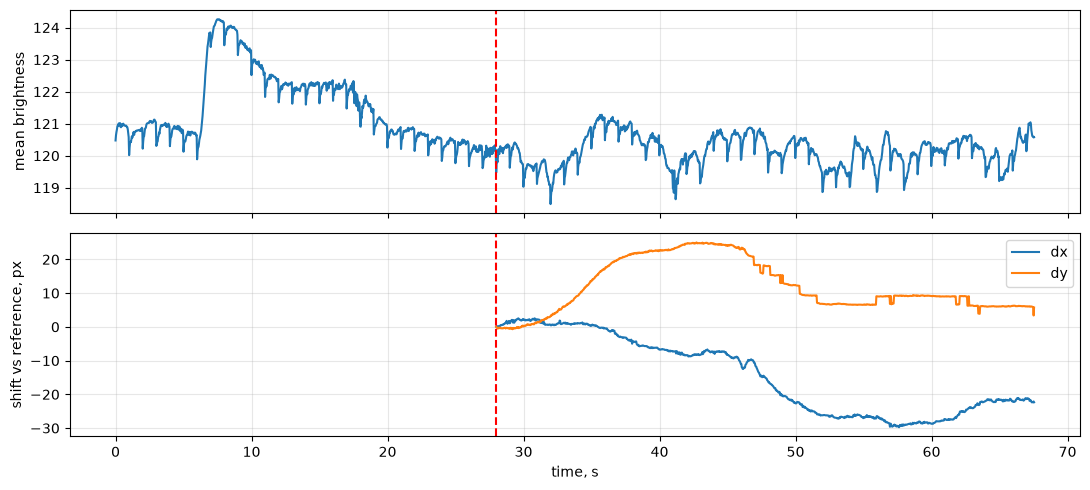

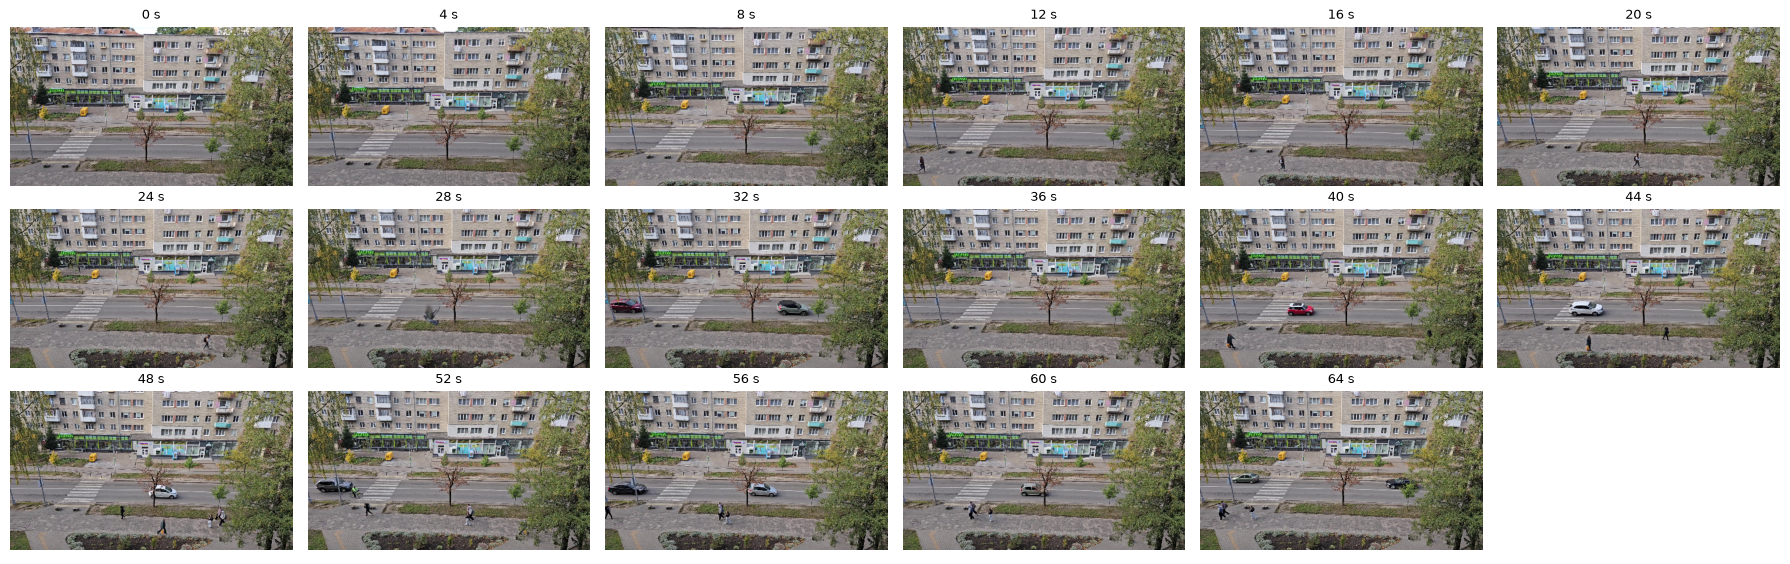

In [2]:
# Cell 2 - video check
cap = cv2.VideoCapture(str(VIDEO)); fps = cap.get(cv2.CAP_PROP_FPS) or 30
n_rep = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); W0, H0 = int(cap.get(3)), int(cap.get(4))
win = None; ref = None; prev = None; t, bright, shift, thumbs = [], [], [], []; i = 0
while True:
    ok, f = cap.read()
    if not ok: break
    g = cv2.cvtColor(cv2.resize(f, (640, 360), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY).astype(np.float32)
    top = g[:140]                                     # buildings: static part of the scene
    if win is None: win = cv2.createHanningWindow(top.shape[::-1], cv2.CV_32F)
    if i == int(START_S * fps): ref = top            # reference = first used frame
    if ref is not None:
        (dx, dy), _ = cv2.phaseCorrelate(ref, top, win); shift.append((i / fps, 3 * dx, 3 * dy))  # full-res px
    t.append(i / fps); bright.append(g.mean())
    if i % int(4 * fps) == 0: thumbs.append((i / fps, cv2.cvtColor(cv2.resize(f, (480, 270)), cv2.COLOR_BGR2RGB)))
    i += 1
cap.release()
sh = np.array(shift)
print(f"size {W0}x{H0} | fps {fps:.2f} | frames read {i} of {n_rep} | duration {i / fps:.1f} s")
print(f"brightness {min(bright):.1f}-{max(bright):.1f}, largest frame-to-frame jump {np.max(np.abs(np.diff(bright))):.2f}")
print(f"camera shift after {START_S:.0f} s: max |dx| {np.abs(sh[:,1]).max():.1f} px, max |dy| {np.abs(sh[:,2]).max():.1f} px (full resolution)")
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(t, bright); ax[0].set_ylabel("mean brightness")
ax[1].plot(sh[:,0], sh[:,1], label="dx"); ax[1].plot(sh[:,0], sh[:,2], label="dy"); ax[1].set_ylabel("shift vs reference, px")
ax[1].set_xlabel("time, s"); ax[1].legend()
for a in ax: a.axvline(START_S, color="red", ls="--"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "var1_step1_check.png", dpi=90); plt.show()
cols = 6; rows = int(np.ceil(len(thumbs) / cols))
fig, ax = plt.subplots(rows, cols, figsize=(3 * cols, 1.9 * rows))
for a in ax.ravel(): a.axis("off")
for a, (tt, im) in zip(ax.ravel(), thumbs): a.imshow(im); a.set_title(f"{tt:.0f} s", fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS / "var1_step1_sheet.png", dpi=80); plt.show()

## Step 2 – Road zone and counting line
Either run `python var1_cars_system.py --setup` in the terminal and click them, or use the values below (measured on this video at 960 × 540) and check them on the preview.

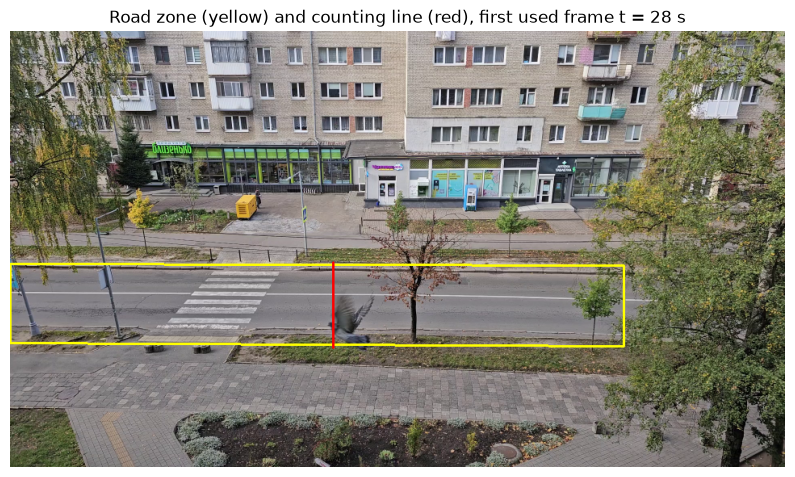

In [3]:
# Cell 3 - road zone + counting line (skip if you used --setup)
roi = {"size": [960, 540],
       "road": [[0, 288], [760, 290], [760, 390], [0, 386]],   # road band, right end stops at the big tree
       "line": [[400, 286], [400, 392]]}                        # vertical line between the crossing and the small tree
(RESULTS / "var1_roi.json").write_text(json.dumps(roi, indent=2))
cap = v.open_video(); ok, f = cap.read(); cap.release()
img = v.resize(f)
cv2.polylines(img, [np.array(roi["road"], np.int32)], True, (0, 255, 255), 2)
cv2.line(img, tuple(roi["line"][0]), tuple(roi["line"][1]), (0, 0, 255), 2)
plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"Road zone (yellow) and counting line (red), first used frame t = {START_S:.0f} s")
plt.savefig(RESULTS / "var1_step2_roi.png", dpi=90, bbox_inches="tight"); plt.show()

## Step 3 – Calibrate the car filter (all filters open, then look at the areas and shapes)

{
  "video": "var1_cars.mp4",
  "frames": 1188,
  "duration_s": 39.6,
  "ids_total": 41,
  "counted_total": 14,
  "counted_per_direction": {
    "L->R": 12,
    "R->L": 2
  },
  "start_s": 28.0,
  "max_cars_in_frame": 4,
  "mean_cars_in_frame": 1.27,
  "rejected": {
    "small": 8701,
    "large": 0,
    "aspect": 0,
    "solidity": 0
  },
  "mean_detect_ms": 12.94,
  "mean_frame_ms": 24.96,
  "system_fps": 31.7,
  "window": false,
  "params": {
    "HISTORY": 300,
    "VAR_THR": 25,
    "MIN_AREA": 200,
    "MAX_AREA": 1000000000,
    "ASPECT": [
      0,
      99
    ],
    "MIN_SOLIDITY": 0,
    "MAX_DIST": 80,
    "MIN_HITS": 5,
    "MAX_MISSED": 10
  }
}


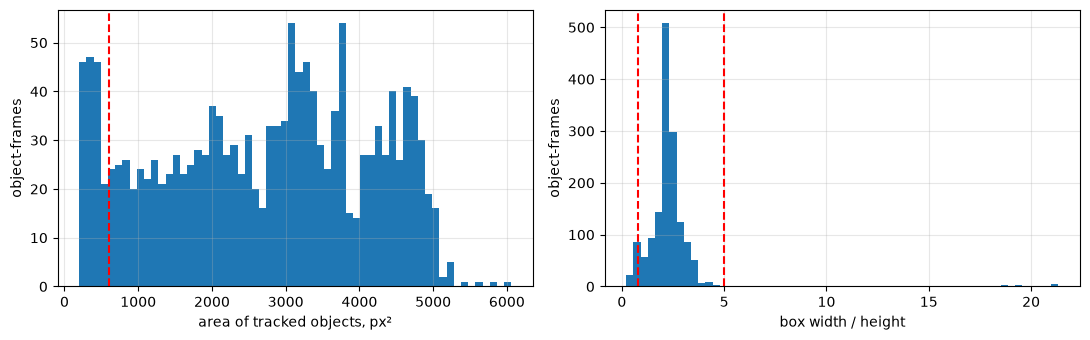

area percentiles 5/50/95: [ 366. 2846. 4792.] | aspect 5/50/95: [0.76 2.21 3.43]


In [9]:
# Cell 4 - calibration run with the filter open
s_open = v.main(show=False, tag="_open", MIN_AREA=200, MAX_AREA=10**9, ASPECT_MIN=0, ASPECT_MAX=99, MIN_SOLIDITY=0)
obj = list(csv.DictReader(open(RESULTS / "var1_objects_open.csv")))
area = np.array([float(o["area"]) for o in obj]); asp = np.array([int(o["w"]) / max(int(o["h"]), 1) for o in obj])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(area, bins=60); ax[0].axvline(v.MIN_AREA, color="red", ls="--"); ax[0].set_xlabel("area of tracked objects, px²")
ax[1].hist(asp, bins=60); ax[1].axvline(v.ASPECT_MIN, color="red", ls="--"); ax[1].axvline(v.ASPECT_MAX, color="red", ls="--")
ax[1].set_xlabel("box width / height")
for a in ax: a.set_ylabel("object-frames"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "var1_step3_calibration.png", dpi=90); plt.show()
print("area percentiles 5/50/95:", np.percentile(area, [5, 50, 95]).round(0), "| aspect 5/50/95:", np.percentile(asp, [5, 50, 95]).round(2))

## Step 4 – Run the system with the chosen parameters (no window = true FPS)

In [10]:
# Cell 5 - main run
s = v.main(show=False)
print({k: s[k] for k in ["frames", "ids_total", "counted_total", "counted_per_direction", "max_cars_in_frame", "rejected", "system_fps"]})

{
  "video": "var1_cars.mp4",
  "frames": 1188,
  "duration_s": 39.6,
  "ids_total": 23,
  "counted_total": 15,
  "counted_per_direction": {
    "L->R": 12,
    "R->L": 3
  },
  "start_s": 28.0,
  "max_cars_in_frame": 3,
  "mean_cars_in_frame": 1.06,
  "rejected": {
    "small": 8980,
    "large": 0,
    "aspect": 22,
    "solidity": 48
  },
  "mean_detect_ms": 15.97,
  "mean_frame_ms": 31.41,
  "system_fps": 25.4,
  "window": false,
  "params": {
    "HISTORY": 300,
    "VAR_THR": 25,
    "MIN_AREA": 600,
    "MAX_AREA": 40000,
    "ASPECT": [
      0.8,
      5.0
    ],
    "MIN_SOLIDITY": 0.5,
    "MAX_DIST": 80,
    "MIN_HITS": 5,
    "MAX_MISSED": 10
  }
}
{'frames': 1188, 'ids_total': 23, 'counted_total': 15, 'counted_per_direction': {'L->R': 12, 'R->L': 3}, 'max_cars_in_frame': 3, 'rejected': {'small': 8980, 'large': 0, 'aspect': 22, 'solidity': 48}, 'system_fps': 25.4}


## Step 5 – Ground truth and evaluation
First run `python var1_annotate.py` in the terminal (press 1 / 2 when a car crosses the red line). Then run this cell.

In [11]:
# Cell 6 - match the program's crossings with the ground truth
def match(det_file, gt_file=RESULTS / "var1_gt_crossings.csv", tol=1.0):
    gt = list(csv.DictReader(open(gt_file))); det = list(csv.DictReader(open(det_file)))
    used, tp, pairs = set(), 0, []
    for g in gt:
        c = [(abs(float(d["time_s"]) - float(g["time_s"])), j) for j, d in enumerate(det)
             if j not in used and d["direction"] == g["direction"]]
        c = [x for x in c if x[0] <= tol]
        if c:
            dt, j = min(c); used.add(j); tp += 1; pairs.append((g["time_s"], det[j]["time_s"], g["direction"]))
    fp = [d for j, d in enumerate(det) if j not in used]
    fn = [g for g in gt if (g["time_s"], g["direction"]) not in {(p[0], p[2]) for p in pairs}]
    return dict(true=len(gt), counted=len(det), TP=tp, FP=len(fp), FN=len(fn),
                precision=round(tp / max(len(det), 1), 2), recall=round(tp / max(len(gt), 1), 2)), fp, fn

if (RESULTS / "var1_gt_crossings.csv").exists():
    res, fp, fn = match(RESULTS / "var1_crossings.csv")
    print(res)
    print("false counts (check these times in var1_output.mp4):", [(d["time_s"], d["direction"]) for d in fp])
    print("missed cars:", [(g["time_s"], g["direction"]) for g in fn])
else:
    print("No ground truth yet: run  python var1_annotate.py  first")

{'true': 15, 'counted': 15, 'TP': 15, 'FP': 0, 'FN': 0, 'precision': 1.0, 'recall': 1.0}
false counts (check these times in var1_output.mp4): []
missed cars: []


## Step 6 – Experiment: one parameter at a time

In [12]:
# Cell 7 - parameter experiment (about 1 minute per run)
rows = []
for name, values in {"MIN_HITS": [3, 5, 10], "MAX_MISSED": [5, 10, 30], "HISTORY": [100, 300, 500]}.items():
    for val in values:
        st = v.main(show=False, tag=f"_{name}_{val}", **{name: val})
        r = dict(parameter=name, value=val, ids=st["ids_total"], counted=st["counted_total"], fps=st["system_fps"])
        if (RESULTS / "var1_gt_crossings.csv").exists():
            r.update(match(RESULTS / f"var1_crossings_{name}_{val}.csv")[0])
        rows.append(r); print(r)
with open(RESULTS / "var1_experiment.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[-1].keys())); w.writeheader(); w.writerows(rows)

{
  "video": "var1_cars.mp4",
  "frames": 1188,
  "duration_s": 39.6,
  "ids_total": 23,
  "counted_total": 15,
  "counted_per_direction": {
    "L->R": 12,
    "R->L": 3
  },
  "start_s": 28.0,
  "max_cars_in_frame": 3,
  "mean_cars_in_frame": 1.1,
  "rejected": {
    "small": 8980,
    "large": 0,
    "aspect": 22,
    "solidity": 48
  },
  "mean_detect_ms": 14.33,
  "mean_frame_ms": 28.26,
  "system_fps": 27.9,
  "window": false,
  "params": {
    "HISTORY": 300,
    "VAR_THR": 25,
    "MIN_AREA": 600,
    "MAX_AREA": 40000,
    "ASPECT": [
      0.8,
      5.0
    ],
    "MIN_SOLIDITY": 0.5,
    "MAX_DIST": 80,
    "MIN_HITS": 3,
    "MAX_MISSED": 10
  }
}
{'parameter': 'MIN_HITS', 'value': 3, 'ids': 23, 'counted': 15, 'fps': 27.9, 'true': 15, 'TP': 15, 'FP': 0, 'FN': 0, 'precision': 1.0, 'recall': 1.0}
{
  "video": "var1_cars.mp4",
  "frames": 1188,
  "duration_s": 39.6,
  "ids_total": 23,
  "counted_total": 15,
  "counted_per_direction": {
    "L->R": 12,
    "R->L": 3
  },
  "st

## Step 7 – Figures for the report

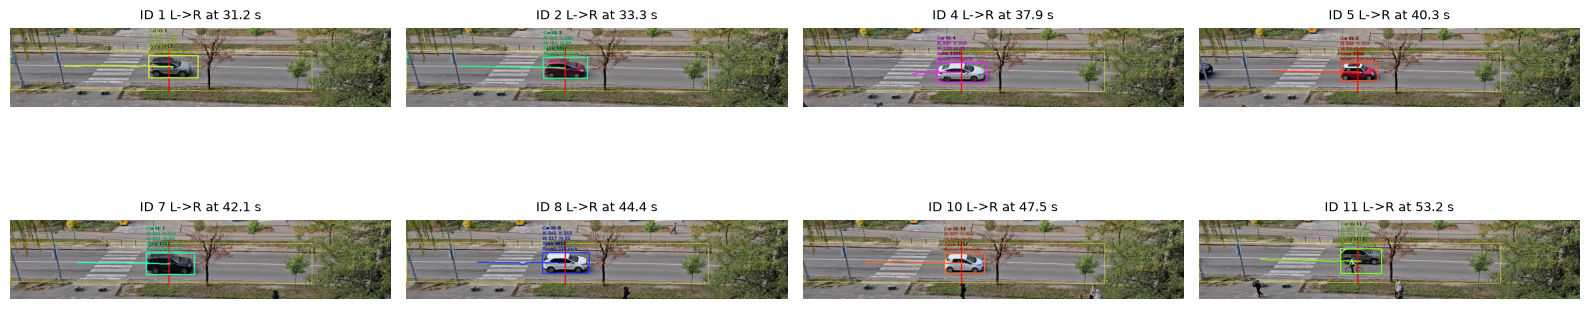

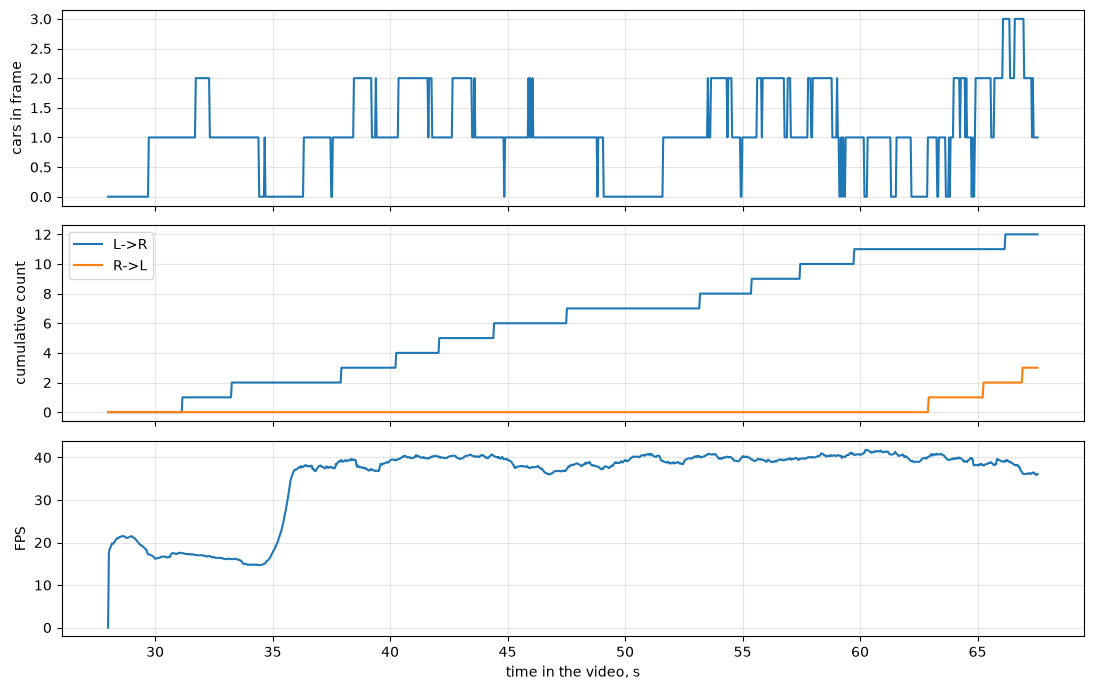

In [13]:
# Cell 8 - snapshots at the crossings + counts and IDs over time
cr = list(csv.DictReader(open(RESULTS / "var1_crossings.csv")))
want = {int(c["frame"]): c for c in cr[:8]}
cap = cv2.VideoCapture(str(RESULTS / "var1_output.mp4")); i = 0; shots = []
while len(shots) < len(want):
    ok, f = cap.read()
    if not ok: break
    if i in want: shots.append((want[i], cv2.cvtColor(f[:, :f.shape[1] // 2], cv2.COLOR_BGR2RGB)))
    i += 1
cap.release()
fig, ax = plt.subplots(2, 4, figsize=(16, 5))
for a in ax.ravel(): a.axis("off")
for a, (c, im) in zip(ax.ravel(), shots): a.imshow(im[230:430]); a.set_title(f"ID {c['id']} {c['direction']} at {float(c['time_s']):.1f} s", fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS / "var1_snapshots.png", dpi=90); plt.show()

fr = list(csv.DictReader(open(RESULTS / "var1_frames.csv")))
tt = [float(r["time_s"]) for r in fr]; keys = [k for k in fr[0] if k.startswith("count_")]
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax[0].plot(tt, [int(r["cars"]) for r in fr]); ax[0].set_ylabel("cars in frame")
for k in keys: ax[1].plot(tt, [int(r[k]) for r in fr], label=k[6:])
ax[1].set_ylabel("cumulative count"); ax[1].legend()
ax[2].plot(tt, [float(r["fps"]) for r in fr]); ax[2].set_ylabel("FPS"); ax[2].set_xlabel("time in the video, s")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "var1_evaluation.png", dpi=90); plt.show()